# Augmented pretraining

> OSSL models pretrained with random instrument effects, as the starting point for fine-tuning

In [ ]:
import pandas as pd, matplotlib.pyplot as plt
from soilspecdl.all import BatchSNV
from soilspecdata.datasets.ossl import load_ossl
from soilspecdata.datasets.ringtrial import load_ringtrial
from ossl_rt_transfer.data import rt_path
from ossl_rt_transfer.pretrain import rt_wns, ossl_xy, pretrain, load_pretrained, pretrain_history
from ossl_rt_transfer.augment import instrument_augs
from ossl_rt_transfer.zero_shot import zero_shot

/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


The cells that read OSSL are marked `#| rtdata`. The outputs on this page come from a local run.

In `05_augment`, the six random instrument effects made the 20-epoch clay and K models less sensitive to instrument effects and improved their zero-shot R² on the ring trial. This notebook trains the augmented models that fine-tuning will start from. With augmentation, each epoch shows the model a different version of every spectrum. The model may then need more epochs than the 80 that `01_pretrain` chose without augmentation.

## Number of epochs

Clay and K train with all six transforms for 80 and 160 epochs, with seed 42 and the other settings of `pretrain`. The 20-epoch runs come from `05_augment`. Each run has its own one-cycle schedule. The table gives the last epoch of each run, and the 80-epoch runs without augmentation for comparison:

In [ ]:
#| rtdata
om = load_ossl().mir(650, 4000)
props, eps = ['clay_perc', 'potassium_cmolkg'], [20, 80, 160]
def aug_fname(p, e, seed=42): return f'ossl_{p}_aug_ep{e}' + ('' if seed == 42 else f'_seed{seed}')
for p in props:
    X, y, _ = ossl_xy(om, p)
    for e in eps: pretrain(X, y, aug_fname(p, e), epochs=e, tfm=[*instrument_augs(rt_wns), BatchSNV()])
runs = {(p, f'augmented, {e}'): aug_fname(p, e) for p in props for e in eps} | {(p, 'not augmented, 80'): f'ossl_{p}_snv_ep80' for p in props}
pd.DataFrame({k: pretrain_history(f).iloc[-1] for k, f in runs.items()}).T.rename_axis(['property', 'epochs']).sort_index().round(3)

train_loss  valid_loss  r2_score
property         epochs                                             
clay_perc        augmented, 160         16.462      22.305     0.925
                 augmented, 20          33.156      37.250     0.874
                 augmented, 80          21.288      25.591     0.914
                 not augmented, 80      14.716      22.462     0.924
potassium_cmolkg augmented, 160          0.019       0.025     0.830
                 augmented, 20           0.037       0.039     0.733
                 augmented, 80           0.025       0.027     0.811
                 not augmented, 80       0.021       0.026     0.822

The learning curves show whether the validation loss still falls at the end of each run. With augmentation, the training loss is on the perturbed spectra and the validation loss on the spectra as measured:

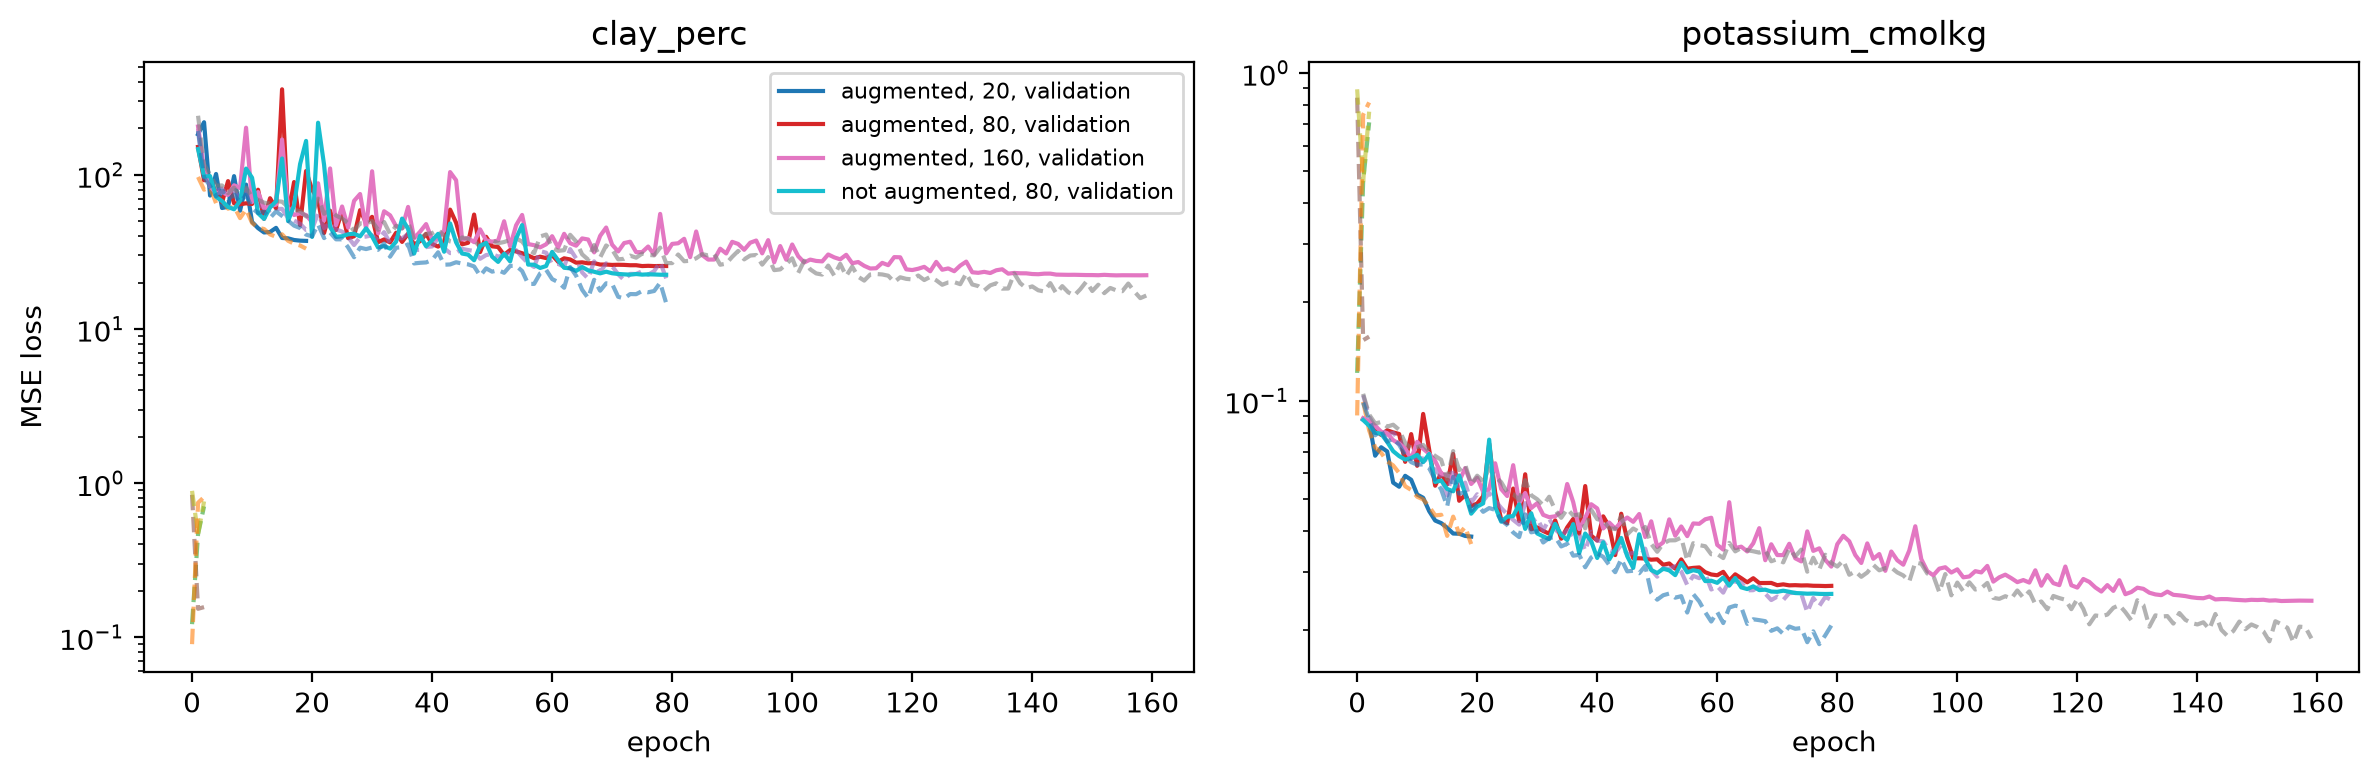

In [ ]:
#| rtdata
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, p in zip(axs, props):
    for (q, label), f in runs.items():
        if q != p: continue
        h = pretrain_history(f).iloc[1:]
        l, = ax.plot(h.index, h.valid_loss, label=f'{label}, validation')
        ax.plot(h.index, h.train_loss, l.get_color(), ls='--', alpha=0.6)
    ax.set(title=p, xlabel='epoch', yscale='log')
axs[0].set_ylabel('MSE loss'); axs[0].legend(fontsize=8)
plt.tight_layout();

Augmentation slows training. At 80 epochs, the augmented models are 0.010 below the unaugmented models in validation R² for clay, and 0.011 below for K. At 160 epochs they reach 0.925 for clay and 0.830 for K, against 0.924 and 0.822 without augmentation at 80 epochs. Going from 80 to 160 epochs gains 0.011 for clay and 0.019 for K, after 0.040 and 0.078 from 20 to 80.

Every curve flattens at the end, because the one-cycle schedule takes the learning rate to zero. The final R² of each run is therefore the guide, not the shape of the last epochs. The base models use 160 epochs. A 320-epoch run would show whether more epochs still help. It was not run.

## Base models

The base models for fine-tuning are the 160-epoch clay and K models of the epoch study above, with seed 42. pH has no augmented model yet. The table gives the validation R² on OSSL at the last epoch, and the median zero-shot R² and |bias| over the 21 ring-trial instruments, as in `02_zero_shot`, beside the unaugmented 80-epoch models of `01_pretrain`. For K, R² is on the `log1p` scale and the bias is in cmol/kg:

In [ ]:
#| rtdata
rtd = load_ringtrial(rt_path())
keys = ['property', 'model']
base = {(p, 'augmented, 160'): aug_fname(p, 160) for p in props} | {(p, 'not augmented, 80'): f'ossl_{p}_snv_ep80' for p in props}
models = {k: load_pretrained(f) for k, f in base.items()}
zs = pd.DataFrame([dict(zip(keys, k), instrument=i, **zero_shot(m, sp, k[0])) for k, m in models.items() for i, sp in rtd.items()])
zs['|bias|'] = zs.bias.abs()
ossl_r2 = pd.Series({k: pretrain_history(f).r2_score.iloc[-1] for k, f in base.items()}, name='OSSL R²').rename_axis(keys)
pd.concat([ossl_r2, zs.groupby(keys)[['R²', '|bias|']].median()], axis=1).round(3)

,,OSSL R²,R²,|bias|
property,model,,,
clay_perc,"augmented, 160",0.925,0.640,4.097
potassium_cmolkg,"augmented, 160",0.830,-0.081,0.197
clay_perc,"not augmented, 80",0.924,0.571,2.666
potassium_cmolkg,"not augmented, 80",0.822,-0.235,0.281


On the ring trial, the augmented 160-epoch models have a higher median zero-shot R² than the unaugmented 80-epoch models: 0.64 against 0.57 for clay, and -0.08 against -0.24 for K. The median |bias| falls for K, from 0.28 to 0.20 cmol/kg, and rises for clay, from 2.7 to 4.1 points.

Longer training lowers the zero-shot R² with and without augmentation. In `05_augment`, at 20 epochs with seed 42, the median R² was 0.69 for clay and 0.16 for K with augmentation, and 0.60 and -0.01 without. More epochs fit OSSL better and transfer less well. Each value comes from one seed, and in `05_augment` two seeds differed by as much as these gaps.